<a href="https://colab.research.google.com/github/mythili-97/VA--Disability-Compensation-Recipients/blob/main/VA_Disability_Compensation_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Disability Compensation Recipients-2025


# **Objective(Problem statment)**

1. This project analyzes country-level VA Disability Compensation data for veterans as of september 30,2025.
2. The objective is to examine the distribution of veterans receiving disability compensation based on service-connected disability(SCD) rating,age group,sex and geographic location.
3.To identify meaningful patterns, trends, and insights from the dataset using exploratory data analysis (EDA)
4. The analysis aims to identify patterns and differences in disability compensation recipients across countries and demograohic groups
5. To create meaningful visualizations that clearly explain the story behind the data

# Outcome

The project give insights into the geographic and demographic distribution of veterans receiving VA Disablility Compensation.It will identify patterns in SCD ratings,age groups,sex and country-level distribution

# Domain
Government and Public Sector

**Dataset Information**

**Source:** Data.Gov
**Link**:https://catalog.data.gov/dataset/fy-2025-disability-compensation-recipients-by-county

**Year / Timeline:** Data collected during September 2025

**Dataset Column/features Description:**


*  FIPS code-Code of the veterans
*  State-State of the veterans
*  Country Name-Country of the veterans
*  Total-Total compensation
*  SCD rating-rating for compensation of recipients
*  Age-Age of the veterans
*  Gender-Gender of the veterans










# Stages for DA Project

## Stage 1 – Problem Definition and Dataset Selection




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# **Inital EDA**

<h3>Load Dataset</h3>


In [ ]:
df=pd.read_csv("https://raw.githubusercontent.com/mythili-97/Python-DA-Project/refs/heads/main/python%20project.csv")

<h3>Dataset Description</h3>

In [ ]:
#Number of rows and columns:
df.shape


(3148, 14)

In [ ]:
#Column names:
df.columns

Index(['FIPS code', 'State', 'County Name',
       'Total: Disability Compensation Recipients', 'SCD rating: 0% to 20%',
       'SCD rating: 30% to 40%', 'SCD rating: 50% to 60%',
       'SCD rating: 70% to 90%', 'SCD rating: 100%', 'Age: 17-44',
       'Age: 45-64', 'Age: 65 or older', 'Male', 'Female'],
      dtype='object')

In [ ]:
df.head()

,FIPS code,State,County Name,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
0,1001,Alabama,Autauga,"2,949",420,250,346,924,"1,009",763,"1,278",908,"2,382",567
1,1003,Alabama,Baldwin,"7,650","1,590",780,909,"2,249","2,122","1,698","2,591","3,360","6,905",745
2,1005,Alabama,Barbour,646,102,48,75,207,214,108,240,298,564,82
3,1007,Alabama,Bibb,324,52,37,37,115,83,70,118,136,298,26
4,1009,Alabama,Blount,"1,088",182,132,146,342,286,288,326,474,"1,011",77


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3148 entries, 0 to 3147
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   FIPS code                                  3148 non-null   object
 1   State                                      3148 non-null   object
 2   County Name                                3148 non-null   object
 3   Total: Disability Compensation Recipients  3135 non-null   object
 4   SCD rating: 0% to 20%                      2984 non-null   object
 5   SCD rating: 30% to 40%                     2820 non-null   object
 6   SCD rating: 50% to 60%                     2833 non-null   object
 7   SCD rating: 70% to 90%                     3027 non-null   object
 8   SCD rating: 100%                           2987 non-null   object
 9   Age: 17-44                                 2966 non-null   object
 10  Age: 45-64                          

In [ ]:
#Converting numeric columns:
numeric_cols=['Total: Disability Compensation Recipients','SCD rating: 0% to 20%' , 'SCD rating: 30% to 40%','SCD rating: 50% to 60%','SCD rating: 70% to 90%','SCD rating: 100%','Age: 17-44','Age: 45-64','Age: 65 or older','Male','Female']
df[numeric_cols]=df[numeric_cols].apply(pd.to_numeric,errors='coerce')


Numeric columns are in object data type initially so it is changed to float64 due to missing values.

In [ ]:
df[numeric_cols].dtypes

,0
Total: Disability Compensation Recipients,float64
SCD rating: 0% to 20%,float64
SCD rating: 30% to 40%,float64
SCD rating: 50% to 60%,float64
SCD rating: 70% to 90%,float64
SCD rating: 100%,float64
Age: 17-44,float64
Age: 45-64,float64
Age: 65 or older,float64
Male,float64


In [ ]:
df.describe()

,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
count,2050.000000,2687.000000,2685.000000,2674.000000,2595.000000,2577.000000,2556.000000,2506.000000,2512.000000,1673.000000,2499.000000
mean,358.702439,195.077410,146.912849,151.201945,216.779576,194.999612,188.963224,222.886672,277.488854,423.111775,133.220488
std,254.899449,209.147242,190.469719,191.043927,219.457555,205.216800,213.652232,217.566182,236.900892,236.614067,184.655527
min,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,48.000000,10.000000
25%,147.000000,53.000000,33.000000,35.000000,63.000000,54.000000,46.000000,69.000000,94.750000,235.000000,26.000000
50%,310.500000,109.000000,67.000000,72.000000,136.000000,116.000000,101.000000,142.000000,198.000000,365.000000,55.000000
75%,525.750000,258.500000,171.000000,180.000000,293.000000,258.000000,241.000000,298.750000,391.250000,586.000000,144.000000
max,999.000000,997.000000,996.000000,986.000000,998.000000,999.000000,998.000000,996.000000,999.000000,999.000000,997.000000


In [ ]:
df.describe(include='all')

,FIPS code,State,County Name,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
count,3148,3148,3148,2050.000000,2687.000000,2685.000000,2674.000000,2595.000000,2577.000000,2556.000000,2506.000000,2512.000000,1673.000000,2499.000000
unique,3148,55,1859,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Unknown,Texas,Washington,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,254,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,358.702439,195.077410,146.912849,151.201945,216.779576,194.999612,188.963224,222.886672,277.488854,423.111775,133.220488
std,NaN,NaN,NaN,254.899449,209.147242,190.469719,191.043927,219.457555,205.216800,213.652232,217.566182,236.900892,236.614067,184.655527
min,NaN,NaN,NaN,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,48.000000,10.000000
25%,NaN,NaN,NaN,147.000000,53.000000,33.000000,35.000000,63.000000,54.000000,46.000000,69.000000,94.750000,235.000000,26.000000
50%,NaN,NaN,NaN,310.500000,109.000000,67.000000,72.000000,136.000000,116.000000,101.000000,142.000000,198.000000,365.000000,55.000000
75%,NaN,NaN,NaN,525.750000,258.500000,171.000000,180.000000,293.000000,258.000000,241.000000,298.750000,391.250000,586.000000,144.000000


In [ ]:
#Checking missing values:
df.isnull().sum()

,0
FIPS code,0
State,0
County Name,0
Total: Disability Compensation Recipients,1098
SCD rating: 0% to 20%,461
SCD rating: 30% to 40%,463
SCD rating: 50% to 60%,474
SCD rating: 70% to 90%,553
SCD rating: 100%,571
Age: 17-44,592


<h4>Missing Value Handling:</h4> The dataset contains suppressed values in several disability compensation, age, and gender columns. According to the source documentation, blank values are used to protect Veteran confidentiality. Therefore, missing values were retained as NaN rather than being replaced with zero or statistical estimates such as median,mode. Rows were excluded only from specific analyses when the required variable was unavailable.

In [ ]:
#Handling null values:
df=df.replace(r'^s*$',np.nan,regex=True)

If a cell contains an empty string or only spaces it can convert it to nan

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.skew(numeric_only=True)

,0


When skewness is 0 it is roughly symmetrical and follows a normal distribution

In [ ]:
df.kurtosis(numeric_only=True)

,0


In [ ]:
import pandas as pd

object_cols = [
    col for col in df.select_dtypes(include="object").columns
    if col.strip().lower() != "fips code"
]
for col in object_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
print(df.dtypes)

FIPS code                                     object
State                                        Float64
County Name                                  Float64
Total: Disability Compensation Recipients      Int64
SCD rating: 0% to 20%                          Int64
SCD rating: 30% to 40%                         Int64
SCD rating: 50% to 60%                         Int64
SCD rating: 70% to 90%                         Int64
SCD rating: 100%                               Int64
Age: 17-44                                     Int64
Age: 45-64                                     Int64
Age: 65 or older                               Int64
Male                                           Int64
Female                                         Int64
dtype: object


When kurtosis is zero(mesokurtic)they have similar tails and peak to normal distribution.

In [ ]:
#Potential outliers:
numerical_cols=[
    col for col in df.select_dtypes(include="number").columns
    if col.lower()!="FIPS code "
]
outlier_results=[]
for col in numerical_cols:
  data=df[col].dropna()
  Q1=data.quantile(0.25)
  Q3=data.quantile(0.75)
  IQR=Q3-Q1
  lower_limit=Q1-1.5*IQR
  upper_limit=Q3+1.5*IQR
  outliers=data[
      (data<lower_limit)|(data>upper_limit)
  ]
  outlier_results.append({
     "column":col,
     "Lower Limit":round(lower_limit,2),
     "Upper Limit":round(upper_limit,2),
     "Outlier Count":len(outliers)
  })
outlier_df=pd.DataFrame(outlier_results)
print("Potential outliers in each column:")
display(outlier_df)

Potential outliers in each column:


,column,Lower Limit,Upper Limit,Outlier Count
0,State,NaN,NaN,0
1,County Name,NaN,NaN,0
2,Total: Disability Compensation Recipients,-1823.50,3656.50,405
3,SCD rating: 0% to 20%,-419.25,850.75,351
4,SCD rating: 30% to 40%,-221.50,462.50,354
5,SCD rating: 50% to 60%,-236.00,492.00,363
6,SCD rating: 70% to 90%,-557.25,1124.75,398
7,SCD rating: 100%,-498.00,998.00,411
8,Age: 17-44,-513.62,997.38,411
9,Age: 45-64,-612.00,1236.00,385


In [ ]:
#Converting data types:
import pandas as pd
numerical_cols = [
    col for col in df.columns
    if col not in ["FIPS code", "State", "County Name"]
]
for col in numerical_cols:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

print(df.dtypes)

FIPS code                                    object
State                                        object
County Name                                  object
Total: Disability Compensation Recipients     Int64
SCD rating: 0% to 20%                         Int64
SCD rating: 30% to 40%                        Int64
SCD rating: 50% to 60%                        Int64
SCD rating: 70% to 90%                        Int64
SCD rating: 100%                              Int64
Age: 17-44                                    Int64
Age: 45-64                                    Int64
Age: 65 or older                              Int64
Male                                          Int64
Female                                        Int64
dtype: object


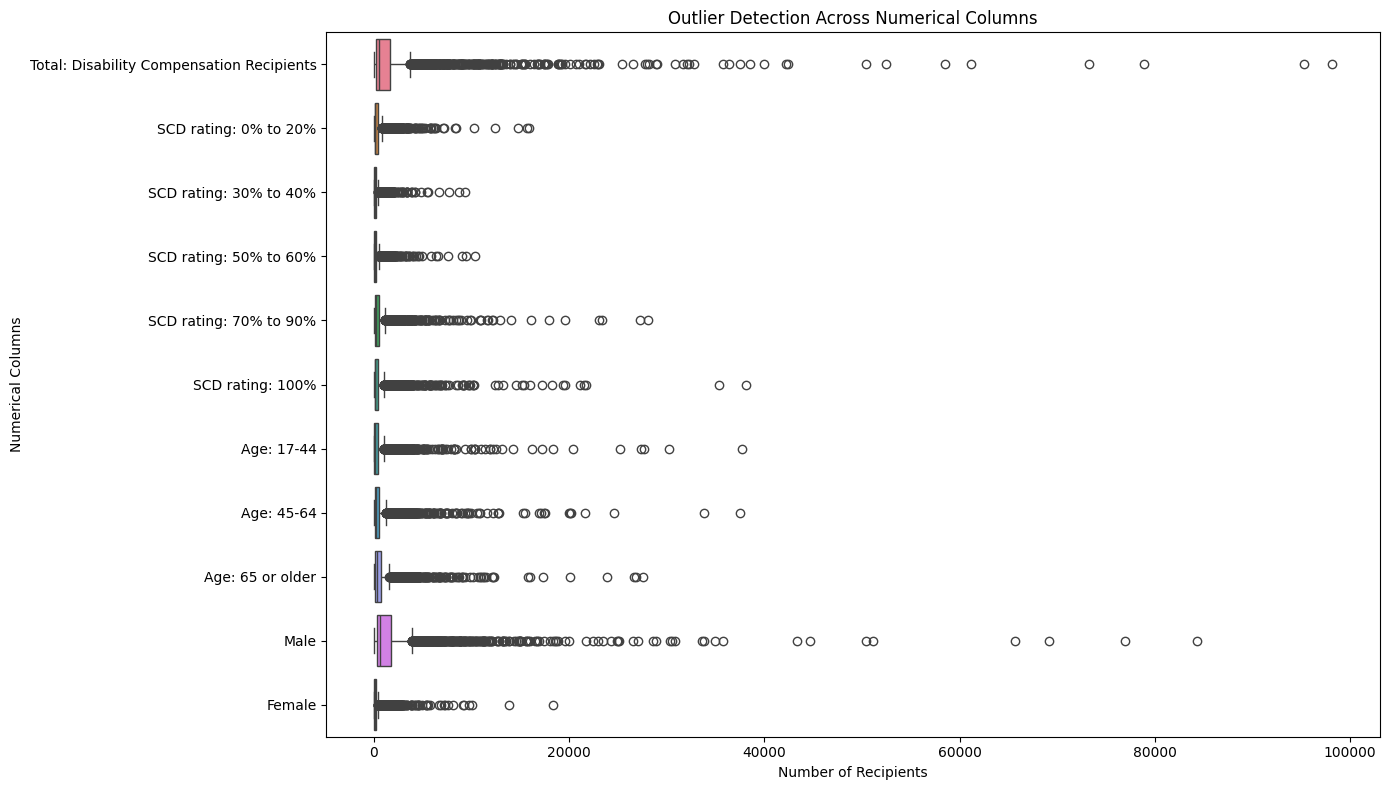

In [ ]:
#Outlier Detection:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(14, 8))
sns.boxplot(data=df[numerical_cols], orient="h", showfliers=True)
plt.title("Outlier Detection Across Numerical Columns")
plt.xlabel("Number of Recipients")
plt.ylabel("Numerical Columns")
plt.tight_layout()
plt.show()

**Outlier Analysis:**Using IQR method potential outliers are identified for numerical columns.Box plot visualizations shows several extreme values particularly in total disability compensation recepients and male counts.


In [ ]:
# Define column groups
scd_cols = [
    col for col in df.columns
    if col.startswith("SCD")
]

gender_cols = ["Male", "Female"]

age_cols = [
    col for col in df.columns
    if col.startswith("Age")
]

# Combine numerical count columns
count_cols = scd_cols + gender_cols + age_cols

count_cols += ["Total Disability Compensation Recipients"]

# Remove duplicates and keep only columns present in df
count_cols = list(dict.fromkeys(
    col for col in count_cols if col in df.columns
))

# IQR-based outlier detection
outlier_results = []

for col in count_cols:
    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_limit) | (data > upper_limit)
    ]

    outlier_results.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Column,Lower Limit,Upper Limit,Outlier Count
0,SCD rating: 0% to 20%,-419.250,850.750,351
1,SCD rating: 30% to 40%,-221.500,462.500,354
2,SCD rating: 50% to 60%,-236.000,492.000,363
3,SCD rating: 70% to 90%,-557.250,1124.750,398
4,SCD rating: 100%,-498.000,998.000,411
5,Male,-1823.375,3865.625,350
6,Female,-227.000,453.000,384
7,Age: 17-44,-513.625,997.375,411
8,Age: 45-64,-612.000,1236.000,385
9,Age: 65 or older,-763.000,1581.000,361


In [ ]:
# Select numerical columns, excluding FIPS code
numerical_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col.strip().lower() != "fips code"
]
# Calculate skewness for all numerical columns
skewness_values = df[numerical_cols].skew()

# Display the results
skewness_df = skewness_values.reset_index()
skewness_df.columns = ["Column", "Skewness"]

print(skewness_df)

                                       Column  Skewness
0   Total: Disability Compensation Recipients  8.737075
1                       SCD rating: 0% to 20%  7.874849
2                      SCD rating: 30% to 40%   7.64645
3                      SCD rating: 50% to 60%  7.793616
4                      SCD rating: 70% to 90%  8.512994
5                            SCD rating: 100%   9.72888
6                                  Age: 17-44  9.835368
7                                  Age: 45-64  8.626707
8                            Age: 65 or older  7.394379
9                                        Male  8.160347
10                                     Female  8.936969


**Interpretation for skewness:**Since all the values are greater than 1,it is highly positively skewed(right-skewed)

In [ ]:
#Using Groupby:
df.groupby('State')['Total: Disability Compensation Recipients'].mean()

,Total: Disability Compensation Recipients
State,
Alabama,2119.0
Alaska,895.827586
Arizona,10604.2
Arkansas,906.52
California,8658.155172
Colorado,2192.03125
Connecticut,4091.111111
Delaware,6498.0
District Of Columbia,7384.0


In [ ]:
df.groupby('County Name')['Total: Disability Compensation Recipients'].sum()

,Total: Disability Compensation Recipients
County Name,
Abbeville,637
Acadia,867
Accomack,715
Ada,13151
Adair,1306
...,...
Yukon-Koyukuk,65
Yuma,6410
Zapata,145


Univariate Analysis:

0    2949
1    7650
2     646
3     324
4    1088
Name: Total: Disability Compensation Recipients, dtype: Int64


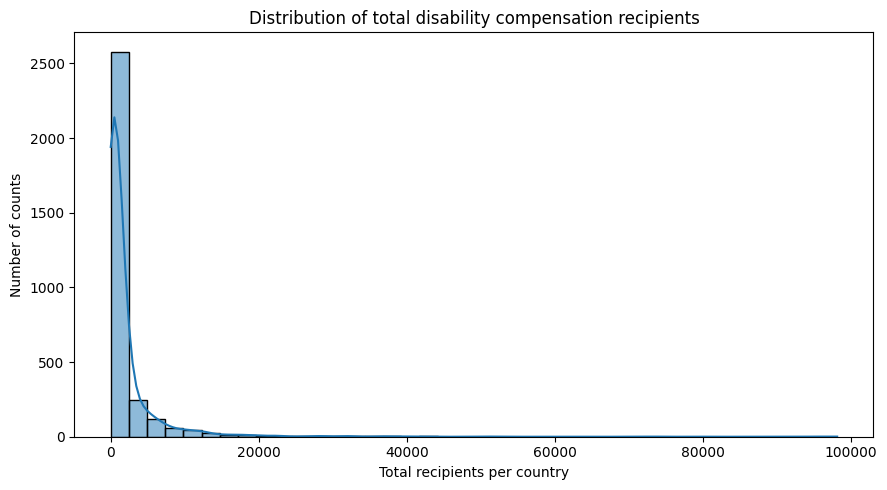

In [ ]:
#Distribution of total recipients:
total_col= "Total: Disability Compensation Recipients"
print(df[total_col].head())
plt.figure(figsize=(9,5))
sns.histplot(data=df,x=total_col,bins=40,kde=True)
plt.title("Distribution of total disability compensation recipients")
plt.xlabel("Total recipients per country")
plt.ylabel("Number of counts")
plt.tight_layout()
plt.show()

Interpretation:
The histogram shows positively skewed distribution of disability compensation recipients across different counts.Mostly they have low recipient counts while smaller number of recipients have higher counts.


Bivariate Analysis:

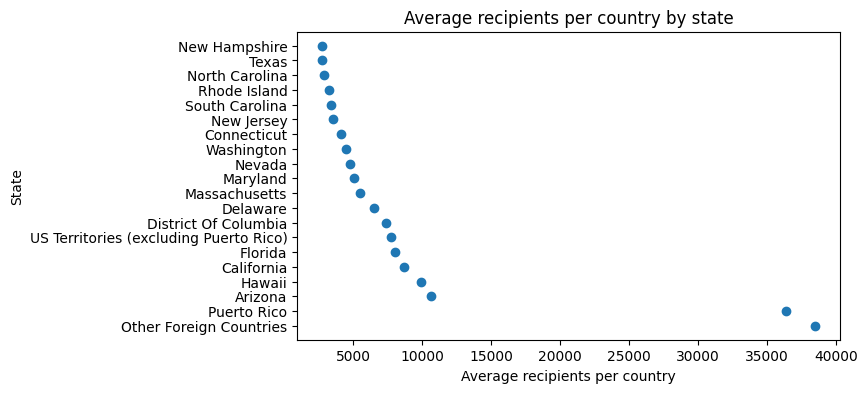

In [ ]:
# Scatter Plot:
state_mean=(df.groupby('State')['Total: Disability Compensation Recipients'].mean()
.sort_values(ascending=False))
top_10_states=state_mean.head(20)
plt.figure(figsize=(7,4))
plt.scatter(top_10_states.values,top_10_states.index)
plt.title("Average recipients per country by state")
plt.xlabel("Average recipients per country")
plt.ylabel("State")
plt.show()

  Interpretation:The scatterplot compares average number of disability compensation recipients across different geographic categories.From this Puerto Rico and other foreign countries shows higher average values than other categories and New hampshire has lowest average among other categories

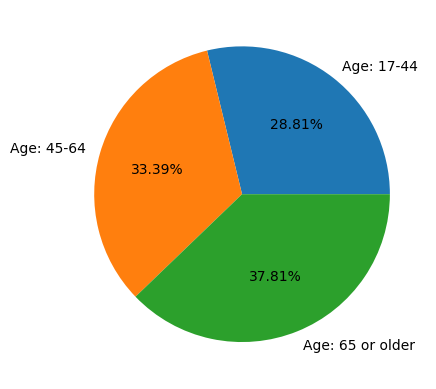

In [ ]:
#Pie Chart:
age_counts=df[
    ['Age: 17-44','Age: 45-64','Age: 65 or older']
].sum()
plt.pie(age_counts,labels=age_counts.index,autopct='%1.2f%%');

Interpretation:The Pie chart shows age distribution among different recipients.From this age group of 65 or above has highest distribution among them

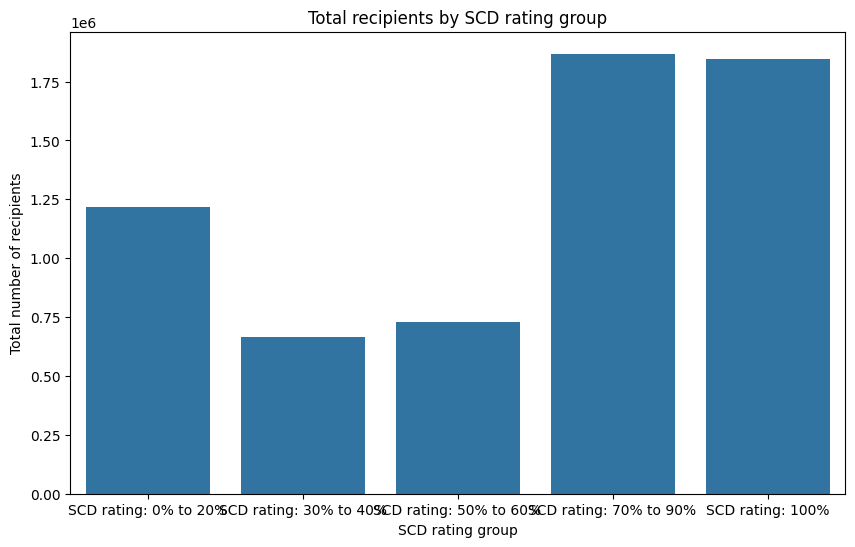

In [ ]:
#Bar Chart:
scd_cols=[
    "SCD rating: 0% to 20%",
    "SCD rating: 30% to 40%",
    "SCD rating: 50% to 60%",
    "SCD rating: 70% to 90%",
    "SCD rating: 100%"
]
scd_totals=df[scd_cols].sum()
plt.figure(figsize=(10,6))
sns.barplot(x=scd_totals.index,y=scd_totals.values)
plt.title("Total recipients by SCD rating group")
plt.xlabel("SCD rating group")
plt.ylabel("Total number of recipients")
plt.show()

Interpretation:The bar chart compares total reported disability compensation recipients across different SCD rating groups.From that,70-90% and 100% rating groups shows higher recipient counts and 30-40% rating group shows lowest count


In [ ]:
#Defining Correlation matrix:
correlation_matrix = df[numerical_cols].corr()

print(type(correlation_matrix))

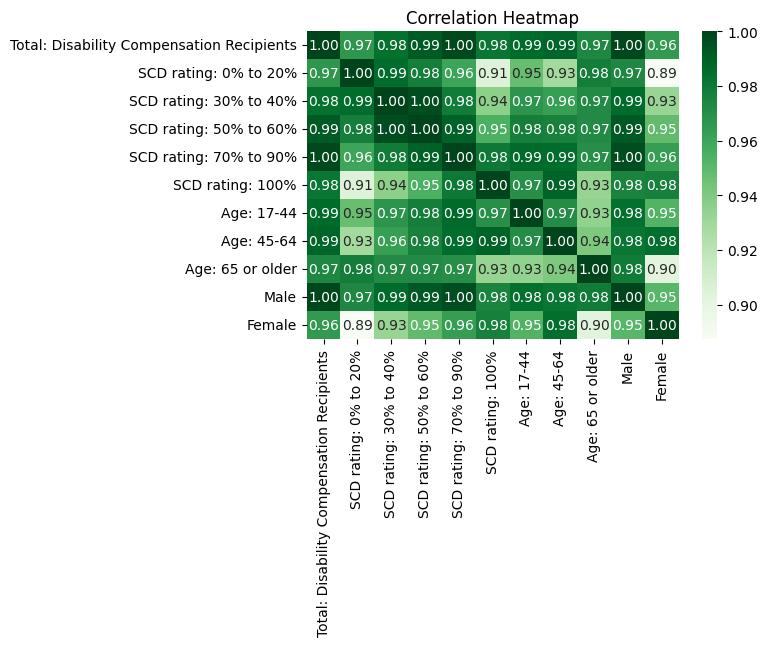

,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
Total: Disability Compensation Recipients,1.000000,0.966947,0.984092,0.992300,0.998049,0.981667,0.986003,0.988439,0.973779,0.998861,0.964971
SCD rating: 0% to 20%,0.966947,1.000000,0.985838,0.977956,0.960080,0.905224,0.947058,0.928509,0.978306,0.973567,0.887303
SCD rating: 30% to 40%,0.984092,0.985838,1.000000,0.996508,0.979160,0.936100,0.967466,0.962814,0.972007,0.985934,0.932436
SCD rating: 50% to 60%,0.992300,0.977956,0.996508,1.000000,0.989682,0.954771,0.977714,0.976046,0.972043,0.992739,0.948499
SCD rating: 70% to 90%,0.998049,0.960080,0.979160,0.989682,1.000000,0.979846,0.986562,0.985630,0.970172,0.996814,0.963432
SCD rating: 100%,0.981667,0.905224,0.936100,0.954771,0.979846,1.000000,0.969922,0.988861,0.933050,0.975016,0.977031
Age: 17-44,0.986003,0.947058,0.967466,0.977714,0.986562,0.969922,1.000000,0.971336,0.934247,0.984550,0.953048
Age: 45-64,0.988439,0.928509,0.962814,0.976046,0.985630,0.988861,0.971336,1.000000,0.940307,0.981513,0.984784
Age: 65 or older,0.973779,0.978306,0.972007,0.972043,0.970172,0.933050,0.934247,0.940307,1.000000,0.978922,0.902864
Male,0.998861,0.973567,0.985934,0.992739,0.996814,0.975016,0.984550,0.981513,0.978922,1.000000,0.951355


In [ ]:
#Correlation Heatmap:
plt.figure(figsize=(6,4))
sns.heatmap(correlation_matrix,annot=True,cmap='Greens',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()
correlation_matrix

Interpretation:The correlation heatmap shows predominately positive relationships among total disability compensation recipients,SCD rating groups,age groups and gender based recipient counts across counties

Multivariate Analysis:


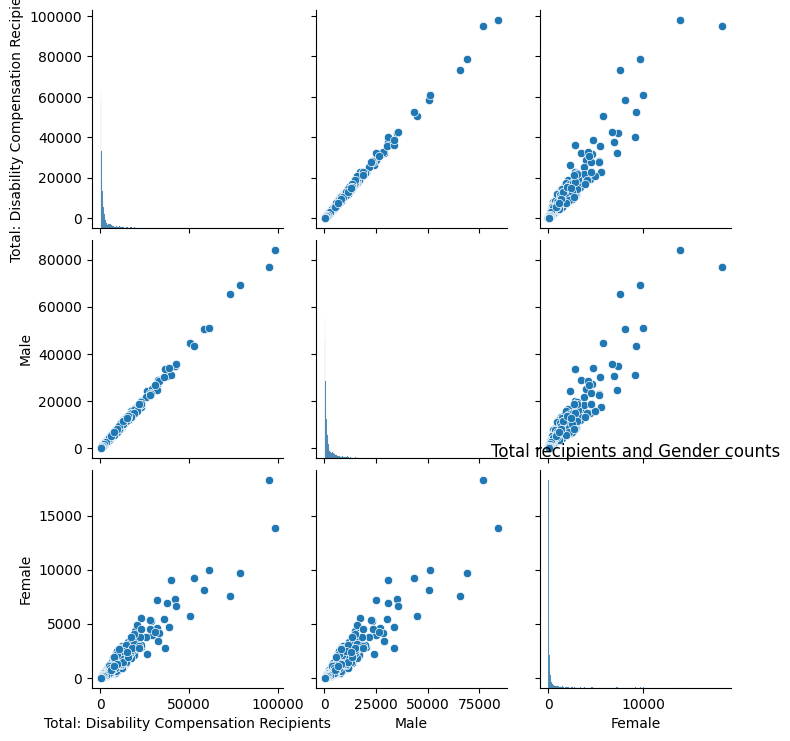

In [ ]:
#Pair plot:
pair_cols=[
    'Total: Disability Compensation Recipients','Male','Female'
]
sns.pairplot(df[pair_cols].dropna(),height=2.5)
plt.title('Total recipients and Gender counts',y=1.02)
plt.show()

Interpretation:The pair plot examines relationships among total disability compensation recipients,male and female recipients across counties.Positive relationship is observed among all these three columns.
The diagonal distributions indicate right-skewed count of data with most counties having comparatively lower counts and smaller number having much higher counts.

In [ ]:
#Converting to CSV file:
import pandas as pd
df.to_csv("VA_Disability_Compensation_cleaned.csv",index=False)

<h3>Key insights and overall analysis:</h3>
The analysis of VA Disability compensation recipients across states,counties,SCD rating groups,age groups and gender.

<b>1.Recipient Distribution:</b>The dataset shows variations in number of disability compensation recipients across states and counties,highlighting differences in the geographical distribution of recipients.

<b>2.SCD Rating Groups:</b>The 70-90% and 100% disability rating groups show relatively high recipient counts in visualizations,while 30-40% group shows comparatively lower counts.

<b>3.Age Distribution:</b>Recipients aged 65 or older represent approximately 37.8% of the age-group distribution,followed by age 45-64 at 33.4% and aged 17-44 at 28.8%.

<b>4.Gender Distribution:</b>The dataset shows differences in male and female recipient counts,with male recipients representing the larger share.This helps to describe the gender composition of the recipient population.

<b>5.Relationship between variables:</b>Correlation analysis indicates positive relationships among several recipient-count variables.These relationships should be interpreted carefully because total recipients and demographic or rating-group counts are mathematically related.

<b>6.Data Quality:</b>Missing and suppressed values,along with highly skewed numerical distributions,may affect comparisons.These limitations should be considered when interpreting the results.

<b>7.Recommendations:</b>Regional service planning,further investigation of differences across locations,improved data completeness and analysis of multiple years of data could support better-informed decisions.





<h3>Conclusion:</h3>Overall,this project demonstrates how Python,exploratory data analysis,Statistical techniques and Power BI visualizations can be used to understand the distribution and demographic composition of VA disability compensation recipients.The findings provide a foundation for further investigation and resource planning,although the dataset alone cannot establish the causes of regional differences or predict future trends.   

**<h2>VA Disability Compensation Recipients</h2>**
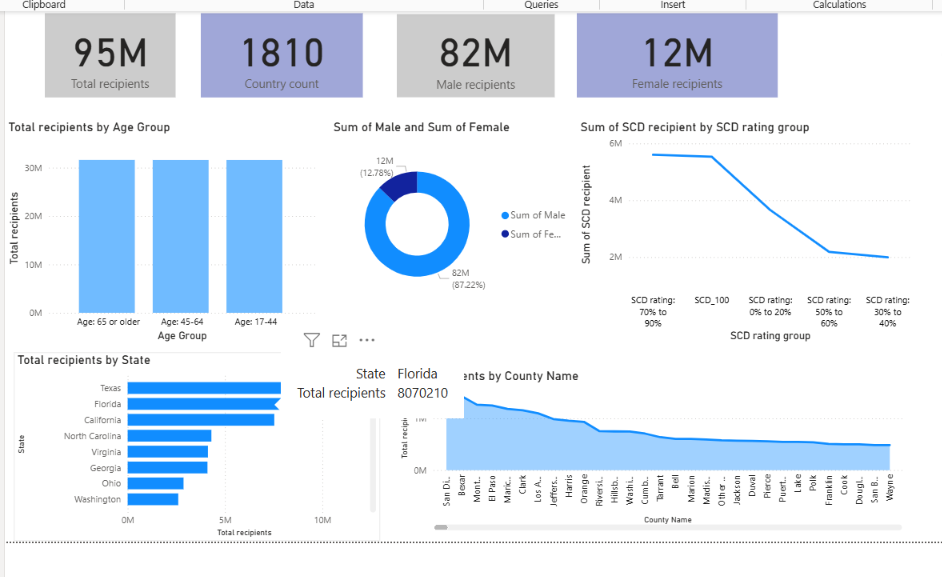